<p align="center"><img src="https://raw.githubusercontent.com/ComputationalChem-USC/AutoMeKin-X/main/banner.jpg" alt="AutoMeKin-X" width="600"></p>

# AutoMeKin-X in Colab: formic acid with PM7 and MACE

This notebook runs a complete, small **AutoMeKin-X** example:

1. **Low level (LL):** reaction discovery for formic acid (FA) with MD simulations at the **PM7** semiempirical level (MOPAC).
2. **High level (HL):** refinement of the LL transition states, minima and products with the **MACE** machine-learning potential (`MACE-omol-0-extra-large-1024`), instead of a quantum chemistry code.
3. **Analysis:** kinetics and interactive reaction networks with [`amk_tools_X`](https://github.com/OmarRodriguezLopez1398/amk_tools_X), after the low level and after MACE.

**Runtime:** go to *Runtime → Change runtime type* and select a **GPU** (a T4 is enough). MACE also runs on CPU, but more slowly.
With the default molecule the whole notebook takes about **15-20 minutes** (installation ~5 min, low level ~4 min, MACE ~5-10 min).

Documentation: [https://computationalchem-usc.github.io/AutoMeKin-X](https://computationalchem-usc.github.io/AutoMeKin-X) · Source code: [https://github.com/ComputationalChem-USC/AutoMeKin-X](https://github.com/ComputationalChem-USC/AutoMeKin-X)

# 1. Installing system packages

In [2]:
%%capture
!sudo apt-get update -y
!sudo apt-get install -y bc gawk gcc gfortran parallel sqlite3 libsqlite3-dev zip
!pip install ase pubchempy

# 2. Installing AutoMeKin-X

In [3]:
%%capture
%cd /content/
!git clone https://github.com/ComputationalChem-USC/AutoMeKin-X.git
%cd /content/AutoMeKin-X
!autoreconf -i
!./configure --prefix=/opt/AutoMeKin
!make && make install
# Use all the available processors
!sed -i 's@ignore=1@ignore=0@g' /opt/AutoMeKin/bin/utils.sh
%env PATH=.:/opt/amk_tools_X/scripts:/opt/AutoMeKin/bin:/opt/AutoMeKin/bin/HLscripts:/opt/AutoMeKin/bin/MOPAC_DEV:/opt/bin:/usr/local/nvidia/bin:/usr/local/cuda/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin:/tools/node/bin:/tools/google-cloud-sdk/bin
%env LIBRARY_PATH=/opt/AutoMeKin/lib:/opt/AutoMeKin/bin/MOPAC_DEV:/usr/local/cuda/lib64/stubs
%env AMK=/opt/AutoMeKin
%env inter=0
%cd /content
!rm -rf /content/AutoMeKin-X

# 3. Making the input files

The default molecule is **formic acid (HCOOH)**. To study another system, change the fields below and pick it from [PubChem](https://pubchem.ncbi.nlm.nih.gov/) by **name**, **cid**, **smiles**, **inchi**, **inchikey** or **formula**. Larger molecules take much longer.

In [4]:
#@title Choose the molecule
molecule = "formic acid" #@param {type:"string"}
identifier = "name" #@param ["name", "cid", "smiles", "inchi", "inchikey", "formula"]

%cd /content
!rm -rf test && mkdir test
%cd /content/test

import pubchempy as pcp

# 3D structure from PubChem
m = pcp.get_compounds(molecule, identifier, record_type='3d')[0]
with open('mol.xyz', 'w') as f:
    f.write(str(len(m.atoms)) + '\n\n')
    for a in m.atoms:
        f.write(f"{a.element} {a.x:.6f} {a.y:.6f} {a.z:.6f}\n")

# Input file: AutoMeKin-X's formic acid example, with MACE as the high-level engine
!curl -sL https://raw.githubusercontent.com/ComputationalChem-USC/AutoMeKin-X/main/examples/FA.dat -o mol.dat
!sed -i 's@FA@mol@;s@imagmin 200@imagmin 50@;s@^HighLevel.*@HighLevel mlip mace@;/^IRCpoints/d' mol.dat
!cat mol.xyz
!cat mol.dat

/content
/content/test
5

O -1.168500 0.182500 0.000000
O 1.114600 0.210300 0.000000
C 0.053800 -0.392700 0.000000
H -0.051100 -1.487500 0.000200
H -1.114200 1.162000 0.000000
--General--
molecule  mol
LowLevel  mopac pm7 
HighLevel mlip mace
HL_rxn_network complete
charge 0
mult   1

--Method--
sampling    MD
ntraj       10 
barrierless yes

--Screening--
imagmin 50
MAPEmax 0.008
BAPEmax 2.5
eigLmax 0.1

--Kinetics--
Energy 150



# 4. Low-level calculations (PM7)

Three iterations of the low-level workflow with 5 tasks per iteration. The input file and every step are explained in the [tutorial](https://computationalchem-usc.github.io/AutoMeKin-X/docs/tutorial.html).

In [5]:
!llcalcs.sh mol.dat 5 3 2



 █████╗           ██╗           ███╗   ███╗        ██╗  ██╗██╗              ██╗  ██╗
██╔══██╗██╗  ██╗██████╗  █████╗ ████╗ ████║ █████╗ ██║ ██╔╝╚═╝██████╗       ╚██╗██╔╝
███████║██║  ██║╚═██╔═╝ ██╔══██╗██╔████╔██║██╔══██╗█████╔╝ ██╗██╔══██╗       ╚███╔╝ 
██╔══██║██║  ██║  ██║   ██║  ██║██║╚██╔╝██║███████║██╔═██╗ ██║██║  ██║█████╗ ██╔██╗ 
██║  ██║██║  ██║  ██║   ██║  ██║██║ ╚═╝ ██║██╔═══╝ ██║  ██╗██║██║  ██║╚════╝██╔╝ ██╗
██║  ██║╚█████╔╝  █████╗╚█████╔╝██║     ██║╚█████╗ ██║  ██║██║██║  ██║      ██║  ██║
╚═╝  ╚═╝ ╚════╝   ╚════╝ ╚════╝ ╚═╝     ╚═╝ ╚════╝ ╚═╝  ╚═╝╚═╝╚═╝  ╚═╝      ╚═╝  ╚═╝

                    revision: dba348e


Number of iterations  = 3
Tasks per iteration   = 5

GENERAL    
Name of the system    = mol
Charge                = 0
Number of atoms       = 5
Low-level MD simul.   = mopac pm7
Low-level TS optim.   = mopac pm7

METHOD     
MD sampling
BBFS algorithm details:
Attempts/single path  = 1 
All atoms are excited 
Temperature (K)       = Automatically selected
Num

*Transition states found at the low level*

In [6]:
!tsll_view.sh

  ts #     File name     w_imag      Energy     w1     w2     w3     w4 traj #   Folder
  ----  ---------------  ------      ------   ----   ----   ----   ---- ------   ------
     1       ts1_batch1   1588i    -35.7105    206    438    461    728      1   batch1
     2      ts2_torsion    459i    -78.1007    573    846   1033   1195   tors  torsion
     3       ts3_batch1   1967i    -24.7272    356    496    642   1064      3   batch1
     4       ts4_batch1   1701i    -54.8122    841    974   1015   1112      5   batch1
     5       ts5_batch1   1418i    -39.7680    319    700    749    845      5   batch1
     6       ts6_batch3    103i    -78.9682    135    186    205    262      8   batch3
     7      ts7_torsion    553i    -60.4522    429    476    515    815   tors  torsion
     8      ts8_torsion    545i    -67.9301    353    477    648    882   tors  torsion
     9       ts9_batch1    426i      7.6671    266    446    663    810      7   batch1
    10      ts10_batch3   2012i 

*Convergence table*

In [7]:
!cat FINAL_LL_mol/convergence.txt

           SYSTEM:  CH2O2
#################################################### 
#                                                  # 
#   Number of trajectories and transition states   # 
#                                                  # 
#################################################### 
 
 Iter #          TSs       ntrajs 
      1            6           50 
      2           11          100 
      3           13          150 


*Coarse-grained reaction network*

In [8]:
!cat FINAL_LL_mol/RXNet.cg

 TS #   DE(kcal/mol)           Reaction path information
 ====   ============           =========================
    7       45.9             MIN    3 ---->       PR1:  CO + H2O        CONN
    8       49.3             MIN    1 ---->       PR1:  CO + H2O        CONN
    9       52.3             MIN    3 ---->       PR7:  H2 + CO2        CONN
   10       61.5             MIN    1 <--->             MIN    3        CONN
   11       68.4             MIN    1 <--->             MIN    3        CONN
   12       94.0             MIN    1 <--->             MIN    6        CONN


*Transition states and minima*

In [9]:
!awk 'BEGINFILE {print "\n"}{print}' FINAL_LL_mol/TSinfo FINAL_LL_mol/MINinfo



TS  #    DE(kcal/mol)
    1        6.051
    2        6.237
    3       10.208
    4       17.976
    5       25.280
    6       33.476
    7       45.938
    8       49.297
    9       52.307
   10       61.513
   11       68.356
   12       93.992
   13       94.512
Conformational isomers are listed in the same line:
4 5 
10 11 


MIN #    DE(kcal/mol)
    1        0.000
    2        8.340
    3       13.627
    4       15.068
    5       23.699
    6       90.493
    7       94.499
Conformational isomers are listed in the same line:
1 2 
3 4 5 
6 7 


*Kinetics at the low level: populations vs time*

/content/test


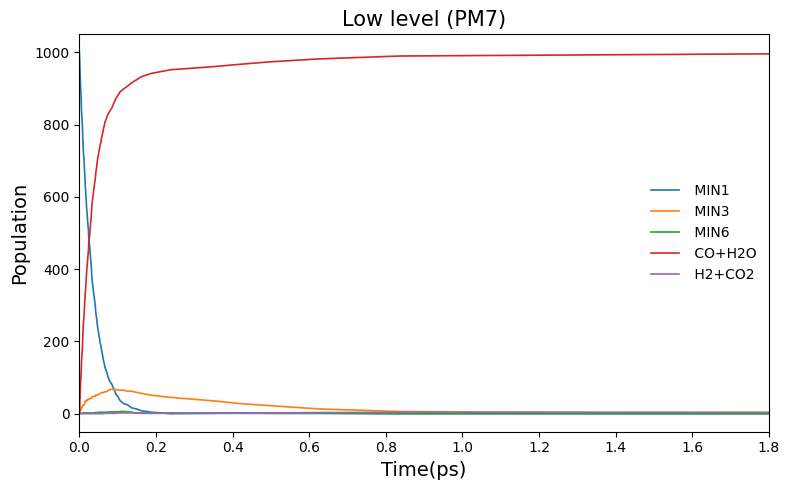

In [10]:
%cd /content/test

import pandas as pd
from matplotlib import pyplot as plt

def plot_kinetics(folder, title):
    data = pd.read_csv(f'{folder}/kinetics.csv')
    x = data.columns[0]
    fig, ax = plt.subplots(figsize=(8, 5))
    for col in data.columns[1:]:
        ax.plot(data[x], data[col], label=col, linewidth=1.2)
    ax.set_xlabel(x, fontsize=14)
    ax.set_ylabel('Population', fontsize=14)
    ax.set_title(title, fontsize=15)
    ax.set_xlim(0, data[x].max())
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()

plot_kinetics('FINAL_LL_mol', 'Low level (PM7)')

# 5. Visualizing the low-level network with `amk_tools_X`

Before refining with MACE, have a look at what the low level found. [`amk_tools_X`](https://github.com/OmarRodriguezLopez1398/amk_tools_X) turns the `FINAL_LL_mol` folder into an interactive dashboard (an HTML file) with the reaction network, the 3D structures, the normal modes and the energy profiles. All its features are explained in section 7.

In [1]:
#@title Installing `amk_tools_X`
%%capture
%cd /opt/
!git clone https://github.com/OmarRodriguezLopez1398/amk_tools_X.git
%cd /opt/amk_tools_X
# Plain install (not -e): the modules go to site-packages, so this running session can import them
!pip install .
%cd /content/test

In [11]:
#@title Helper to show a dashboard inside the notebook
import subprocess
from google.colab import output

def show_dashboard(html_file, height=850):
    """Serve /content/test/HTML and display one of its dashboards."""
    subprocess.run(['fuser', '-k', '8000/tcp'], stderr=subprocess.DEVNULL)
    subprocess.Popen(['python', '-m', 'http.server', '8000'], cwd='/content/test/HTML',
                     stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    output.serve_kernel_port_as_iframe(8000, path='/' + html_file, height=height)

In [12]:
#@title Low-level dashboard
%cd /content/test
!mkdir -p HTML
from os import path
tag = 1
if path.isfile('tsdirLL_mol/KMC/starting_minimum'):
    tag = open('tsdirLL_mol/KMC/starting_minimum').read().split()[0]
!amk_gen_view.py FINAL_LL_mol RXNet.cg --barrierless --paths MIN{tag} --outfile HTML/network_LL.html --title "Low level (PM7)"
show_dashboard('network_LL.html')

/content/test


<IPython.core.display.Javascript object>

# 6. High-level refinement with MACE

The low-level transition states are now re-optimized with the **MACE-OMol** machine-learning interatomic potential, and their IRCs, minima, products and kinetics are recomputed. AutoMeKin-X calls MACE through ASE and [Sella](https://github.com/zadorlab/sella), so no quantum chemistry code is needed. The input file already contains `HighLevel mlip mace` (see section 3).

More details: [Using ML potentials](https://computationalchem-usc.github.io/AutoMeKin-X/docs/mlip.html).

In [13]:
#@title Installing MACE and downloading the model
%%capture
!pip install sella mace-torch
# PyTorch >= 2.6 needs this to load a file shipped with e3nn (harmless otherwise)
!sed -i "s/'constants.pt'))/'constants.pt'), weights_only=False)/" $(python -c "import e3nn, os; print(os.path.join(os.path.dirname(e3nn.__file__), 'o3', '_wigner.py'))")
!mkdir -p /opt/AutoMeKin/models
!curl -L https://github.com/ACEsuit/mace-foundations/releases/download/mace_omol_0/MACE-omol-0-extra-large-1024.model -o /opt/AutoMeKin/models/MACE-omol-0-extra-large-1024.model

In [14]:
#@title Checking the device MACE will use
import torch
if torch.cuda.is_available():
    print('GPU found:', torch.cuda.get_device_name(0))
else:
    print('No GPU found: MACE will run on CPU (slower). Consider Runtime -> Change runtime type -> GPU.')

GPU found: Tesla T4


In [ ]:
%cd /content/test
!hlcalcs.sh mol.dat 2

/content/test


 █████╗           ██╗           ███╗   ███╗        ██╗  ██╗██╗              ██╗  ██╗
██╔══██╗██╗  ██╗██████╗  █████╗ ████╗ ████║ █████╗ ██║ ██╔╝╚═╝██████╗       ╚██╗██╔╝
███████║██║  ██║╚═██╔═╝ ██╔══██╗██╔████╔██║██╔══██╗█████╔╝ ██╗██╔══██╗       ╚███╔╝ 
██╔══██║██║  ██║  ██║   ██║  ██║██║╚██╔╝██║███████║██╔═██╗ ██║██║  ██║█████╗ ██╔██╗ 
██║  ██║██║  ██║  ██║   ██║  ██║██║ ╚═╝ ██║██╔═══╝ ██║  ██╗██║██║  ██║╚════╝██╔╝ ██╗
██║  ██║╚█████╔╝  █████╗╚█████╔╝██║     ██║╚█████╗ ██║  ██║██║██║  ██║      ██║  ██║
╚═╝  ╚═╝ ╚════╝   ╚════╝ ╚════╝ ╚═╝     ╚═╝ ╚════╝ ╚═╝  ╚═╝╚═╝╚═╝  ╚═╝      ╚═╝  ╚═╝

                    revision: dba348e


GENERAL    
Name of the system    = mol
Charge                = 0
Multiplicity          = 1
High-level method     = mace
Number of IRC pts     = 100


CALCULATIONS START HERE

   Running TS opt    
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` o

*High-level (MACE) transition states and minima*

In [ ]:
!awk 'BEGINFILE {print "\n"}{print}' FINAL_ML_mol/TSinfo FINAL_ML_mol/MINinfo

*Coarse-grained reaction network at the MACE level*

In [ ]:
!cat FINAL_ML_mol/RXNet.cg

*Kinetics: low level vs MACE*

In [ ]:
%cd /content/test
plot_kinetics('FINAL_LL_mol', 'Low level (PM7)')
plot_kinetics('FINAL_ML_mol', 'High level (MACE)')

# 7. Exploring the MACE network with `amk_tools_X`

## What the dashboard offers

`amk_gen_view.py` reads a `FINAL_*` folder and writes a self-contained HTML file (no Python server is needed to open it later; JSmol is loaded from the internet). The dashboard has:

- **Interactive network.** Pan and zoom with the mouse. Hovering over a node (minimum `MIN`, product `PR`) or an edge (transition state `TS`) shows its name and energy.
- **3D viewer (JSmol).** Click a node or an edge to see its 3D structure.
- **Normal modes.** For the selected structure, pick a vibrational mode to animate it (for a TS, the imaginary mode shows the reaction coordinate).
- **Coordinates to the clipboard.** The XYZ geometry of the selected structure is copied automatically, ready to paste into an input file.
- **Search by name.** Type a label (for example `TS4` or `MIN3`) to locate it in large networks.
- **Energy profiles.** When paths are requested with `--paths`, the energy profiles along them are shown, and they can be filtered by energy or by the presence of the selected node or edge.

## Options of `amk_gen_view.py`

`amk_gen_view.py FINALDIR RXNFILE [options]`

| Option | What it does |
|---|---|
| `FINALDIR` | Results folder: `FINAL_LL_mol` (low level) or `FINAL_ML_mol` (MACE). |
| `RXNFILE` | Network file: `RXNet` (full), `RXNet.cg` (coarse-grained, equivalent conformers merged) or `RXNet.rel` (only the relevant paths). |
| `--barrierless`, `-b` | Add the barrierless channels from `RXNet.barrless`. |
| `--paths`, `-p [SOURCE] [TARGET]` | Search paths and add the energy profiles. With `SOURCE` and `TARGET`, only the paths connecting them. With only `SOURCE`, all cycles that pass through it. Alone, every path in the network (slow for big networks). Several labels go comma-separated, and products can be given by formula, e.g. `MIN1 H2+CO2,CO+H2O`. |
| `--cutoff_path`, `-c N` | Maximum number of intermediates in a SOURCE→TARGET path (default 4). |
| `--efilter`, `-e E` | Keep only paths whose highest point is below `E` kcal/mol. |
| `--unreduced`, `-u` | Show the whole network, not only the nodes that belong to the selected paths. |
| `--ref_state`, `-rs LABEL` | Use another species (e.g. `MIN3`) as the zero of energy. |
| `--vibrations`, `-v N` | Number of normal modes per structure (`-1`, the default, means all). |
| `--geomolden`, `-ng` | Read the geometries from the MOLDEN files instead of the databases. |
| `--outfile`, `-o FILE` | Name of the HTML file (default `network.html`). |
| `--title`, `-t TEXT` | Title shown on the dashboard. |
| `--resolution`, `-r W,H` | Size of the dashboard in pixels (default `1400,800`). |
| `--fasterlayout`, `-f` | Use a faster layout (spring) for large networks. |

The same tools can be used from Python (`RXReader` and `RXVisualizer` modules), as shown at the end of this section. The full guide is in the [amk_tools_X repository](https://github.com/OmarRodriguezLopez1398/amk_tools_X).

## Build your own dashboard

The defaults below reproduce the MACE network with the energy profiles from `MIN1` to every product. Change the fields and run the cell again to try other options.

In [ ]:
#@title Generate a dashboard
level = "MACE" #@param ["MACE", "LL"]
rxnfile = "RXNet.cg" #@param ["RXNet.cg", "RXNet", "RXNet.rel"]
barrierless = True #@param {type:"boolean"}
source = "MIN1" #@param {type:"string"}
target = "" #@param {type:"string"}
cutoff_path = 4 #@param {type:"integer"}
energy_filter = 0 #@param {type:"number"}
ref_state = "" #@param {type:"string"}
unreduced = False #@param {type:"boolean"}
vibrations = -1 #@param {type:"integer"}
faster_layout = False #@param {type:"boolean"}

import os, shlex
os.chdir('/content/test')
os.makedirs('HTML', exist_ok=True)
folder = {'MACE': 'FINAL_ML_mol', 'LL': 'FINAL_LL_mol'}[level]
outfile = f'network_{level}_custom.html'
cmd = ['amk_gen_view.py', folder, rxnfile, '--outfile', f'HTML/{outfile}',
       '--title', f'{level}: {rxnfile}', '--cutoff_path', str(cutoff_path),
       '--vibrations', str(vibrations)]
if barrierless: cmd.append('--barrierless')
if source.strip():
    cmd += ['--paths', source.strip()] + ([target.strip()] if target.strip() else [])
if energy_filter > 0: cmd += ['--efilter', str(energy_filter)]
if ref_state.strip(): cmd += ['--ref_state', ref_state.strip()]
if unreduced: cmd.append('--unreduced')
if faster_layout: cmd.append('--fasterlayout')
print(' '.join(shlex.quote(c) for c in cmd))
res = subprocess.run(cmd, capture_output=True, text=True)
print(res.stdout[-2000:], res.stderr[-2000:])
show_dashboard(outfile)

## Using `amk_tools_X` from Python

`RXReader` reads the network into a NetworkX graph that contains the energies, geometries and frequencies of every species, so you can do your own analysis. This example lists the species, finds the paths from `MIN1` to the products and draws their energy profiles with Matplotlib.

In [ ]:
%cd /content/test
import RXReader as arx

finaldir = 'FINAL_ML_mol'
data = arx.RX_parser(finaldir, 'RXNet.cg')
G = arx.RX_builder(finaldir, data)

print('Species and energies (kcal/mol):')
for name, props in sorted(G.nodes(data=True), key=lambda n: n[1]['energy']):
    print(f"  {name:6s} {props['energy']:8.2f}")

products = [n for n in G.nodes if n.startswith('PR')]
limits = arx.node_synonym_search(G, [['MIN1'], products])
paths = arx.add_paths(G, limits[0], limits[1], cutoff=4)
print('\nPaths from MIN1 to the products:')
for p in paths:
    print('  ' + ' -> '.join(p))

# Energy profiles with amk_tools_X (the plotter takes the minima/products of each path;
# the TSs are read from the edges of the graph)
from matplotlib import pyplot as plt
node_paths = [[x for x in p if x in G.nodes] for p in paths]
fig, ax = arx.theor_profile_plotter(G, node_paths)
ax.set_ylabel('Energy (kcal/mol)', fontsize=13)
plt.show()

*Save the results*

In [ ]:
%cd /content/test
!zip -qr results.zip FINAL_LL_mol FINAL_ML_mol HTML
print('Download /content/test/results.zip from the Files panel to keep the results and the dashboards.')